In [1]:
import utils.database as db
from utils import cellmath, cellplot
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

frame = 70
data = db.get_frame(frame, db.get_database_path())

cell_data = data["cells"]
dbonds_data = data["directed_bonds"]
vertices_data = data["vertices"]

Average Area difference (Magnitude) =  12.044


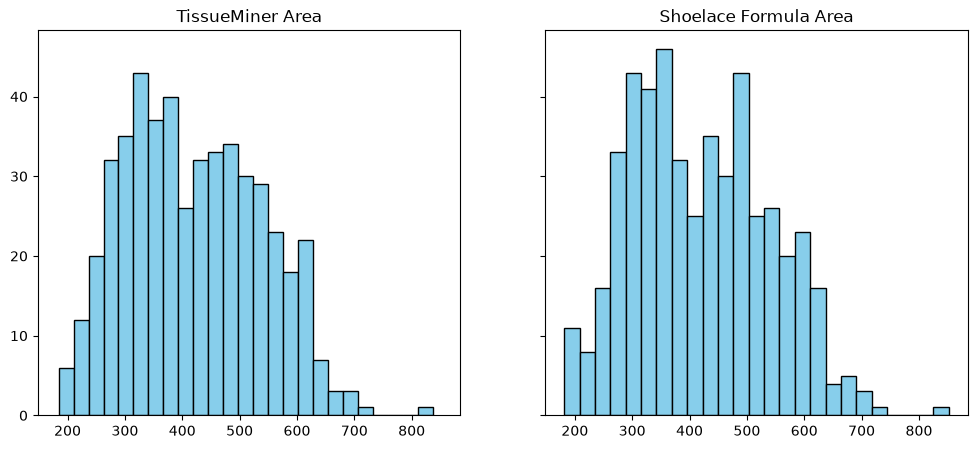

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True , sharey=True, figsize=(12, 5))

cleaned_cell_data = cell_data[cell_data["cell_id"] != 10000]

ax1.hist(cleaned_cell_data["area"], bins=25, color="skyblue", edgecolor="black")
ax1.set_title("TissueMiner Area")

shoelace_areas = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    shoelace_areas.append(cellmath.shoelace_area(vList))


ax2.hist(shoelace_areas, bins=25, color="skyblue", edgecolor="black")
ax2.set_title("Shoelace Formula Area")
    
diff = cleaned_cell_data["area"] - pd.Series(shoelace_areas)

cell_data_area_list  = cleaned_cell_data["area"].tolist()

diff = []
for i, val in enumerate(cell_data_area_list):
    diff.append(shoelace_areas[i] - val)

print("Average Area difference (Magnitude) = ", np.round(np.mean(np.abs(diff)), 3))

Text(0, 0.5, 'Cell Count')

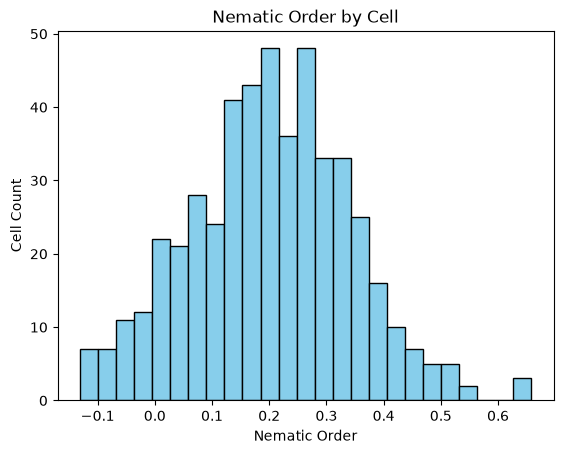

In [3]:
nematic_orders = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    real, imaginary = cellmath.calc_order(vList, 2)
    nematic_orders.append(real)

plt.hist(nematic_orders, bins=25, color="skyblue", edgecolor="black")
plt.title("Nematic Order by Cell")
plt.xlabel("Nematic Order")
plt.ylabel("Cell Count")

10369.556468172485


np.int64(10708)

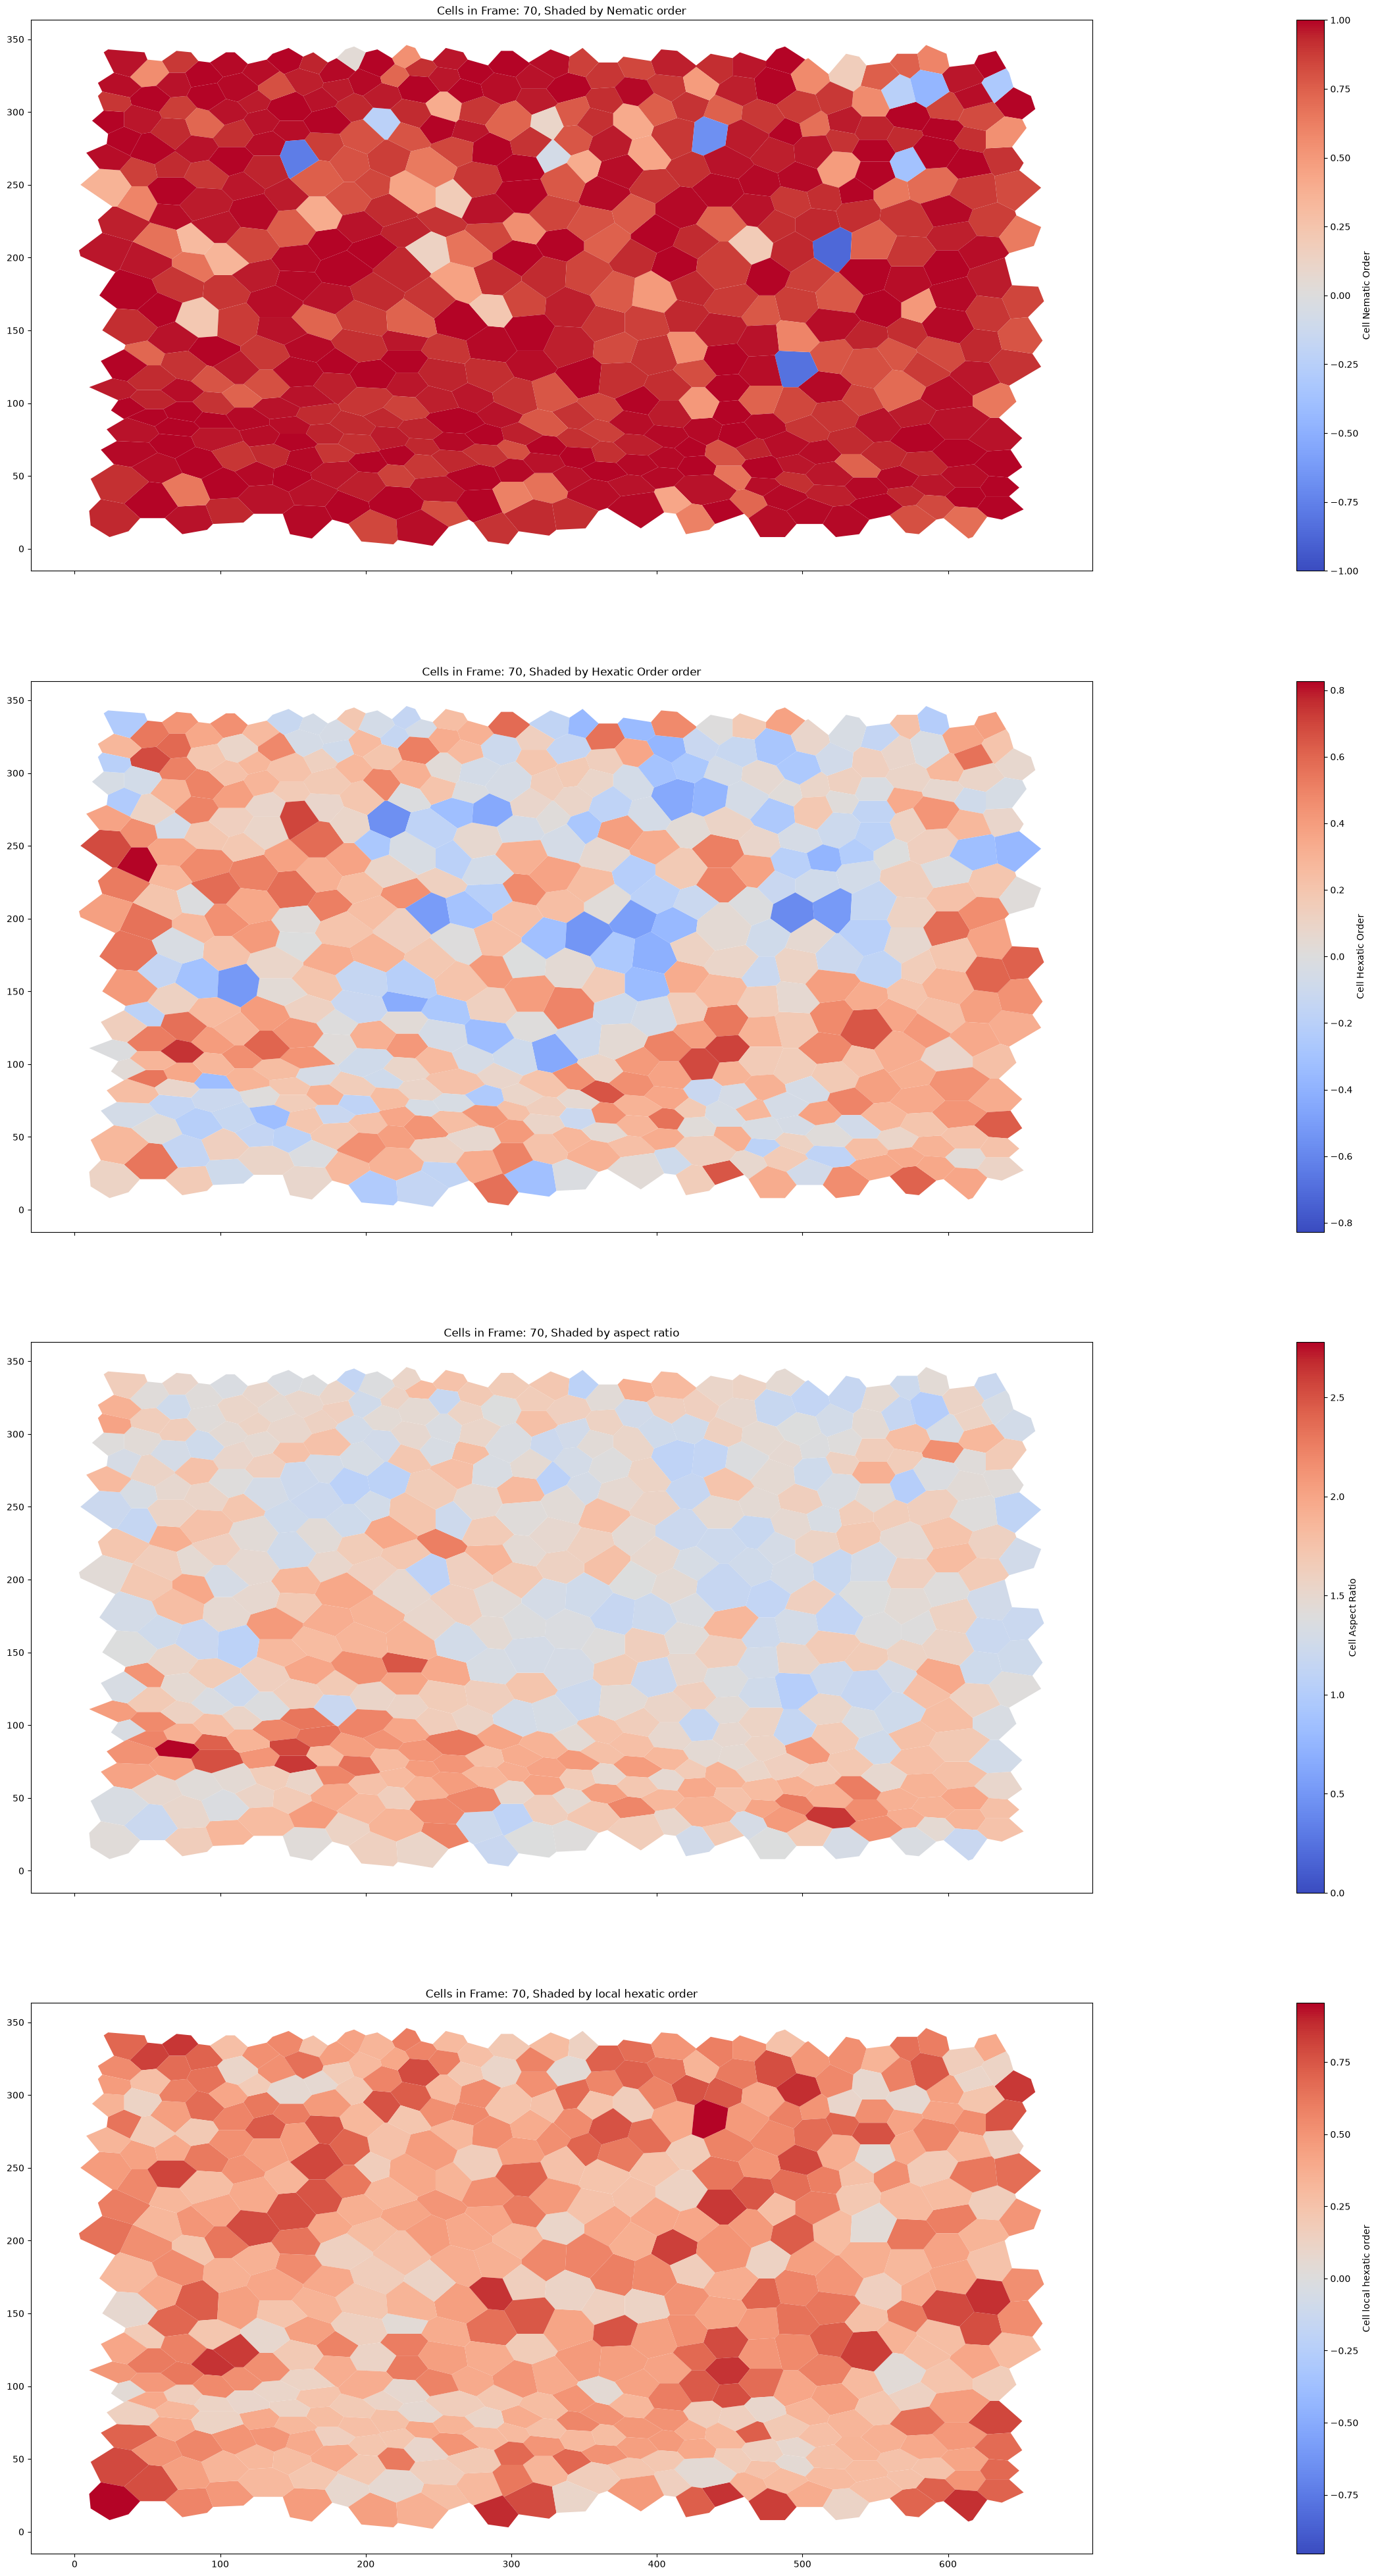

In [4]:

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(100, 50), sharex=True, sharey=True)

n_order_dict = cellmath.nematic_order_dict(cleaned_cell_data, dbonds_data, vertices_data, False)
hexatic_order_dict = cellmath.order_dict(cleaned_cell_data, dbonds_data, vertices_data, 6, False) 
aspect_ratio_dict = cellmath.aspect_ratio_dict(cleaned_cell_data, dbonds_data, vertices_data)
local_hexatic_order_dict = cellmath.local_hexatic_order_dict(cleaned_cell_data, dbonds_data, vertices_data)

cellplot.draw_cell_boundaries(
    ax1,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    n_order_dict,
    border_width=0.001
)

ax1.set_title(f"Cells in Frame: {frame}, Shaded by Nematic order")
cellplot.plotColorBar(ax1, fig, n_order_dict, True, "Cell Nematic Order")

cellplot.draw_cell_boundaries(
    ax2,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    hexatic_order_dict,
    border_width=0.001
)

ax2.set_title(f"Cells in Frame: {frame}, Shaded by Hexatic Order order")
cellplot.plotColorBar(ax2, fig, hexatic_order_dict, True, "Cell Hexatic Order")

cellplot.draw_cell_boundaries(
    ax3,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    aspect_ratio_dict,
    border_width=0.001,
    negative_vals=False
)

ax3.set_title(f"Cells in Frame: {frame}, Shaded by aspect ratio")
cellplot.plotColorBar(ax3, fig, aspect_ratio_dict, False, "Cell Aspect Ratio")

cellplot.draw_cell_boundaries(
    ax4,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    local_hexatic_order_dict,
    border_width=0.001
)

ax4.set_title(f"Cells in Frame: {frame}, Shaded by local hexatic order")
cellplot.plotColorBar(ax4, fig, local_hexatic_order_dict, True, "Cell local hexatic order")

print(np.mean(list(local_hexatic_order_dict)))
max(local_hexatic_order_dict)

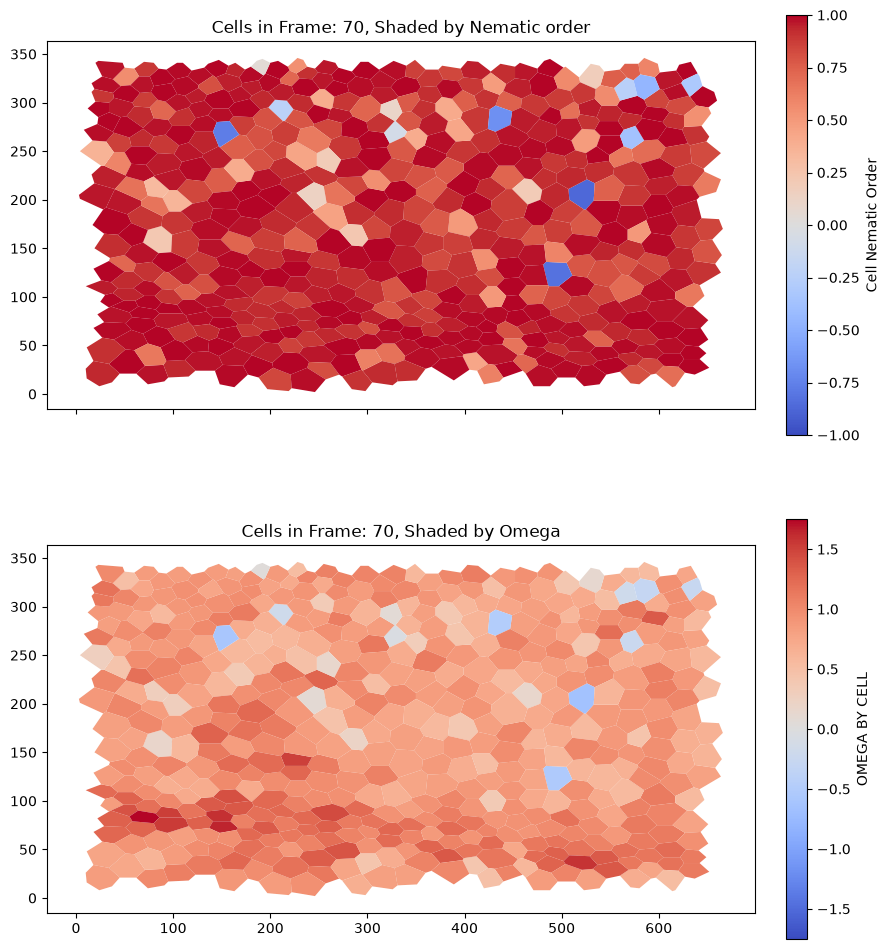

In [5]:

def weighted_order_dict(nematic_order_dict, aspect_ratio_dict):
    avg_aspect_ratio = np.mean(list(aspect_ratio_dict.values()))
    weighted_order_dict = dict()

    for cell_id, n_order in nematic_order_dict.items():
        weighted_order_dict[cell_id] = (
            aspect_ratio_dict[cell_id] * n_order / avg_aspect_ratio
        )

    return weighted_order_dict

w_order_dict = weighted_order_dict(n_order_dict, aspect_ratio_dict)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12), sharex=True, sharey=True)

cellplot.draw_cell_boundaries(
    ax2,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    w_order_dict,
    border_width=0.001
)

ax2.set_title(f"Cells in Frame: {frame}, Shaded by Omega")
cellplot.plotColorBar(ax2, fig, w_order_dict, True, "OMEGA BY CELL")


cellplot.draw_cell_boundaries(
    ax1,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    n_order_dict,
    border_width=0.001
)

ax1.set_title(f"Cells in Frame: {frame}, Shaded by Nematic order")
cellplot.plotColorBar(ax1, fig, n_order_dict, True, "Cell Nematic Order")


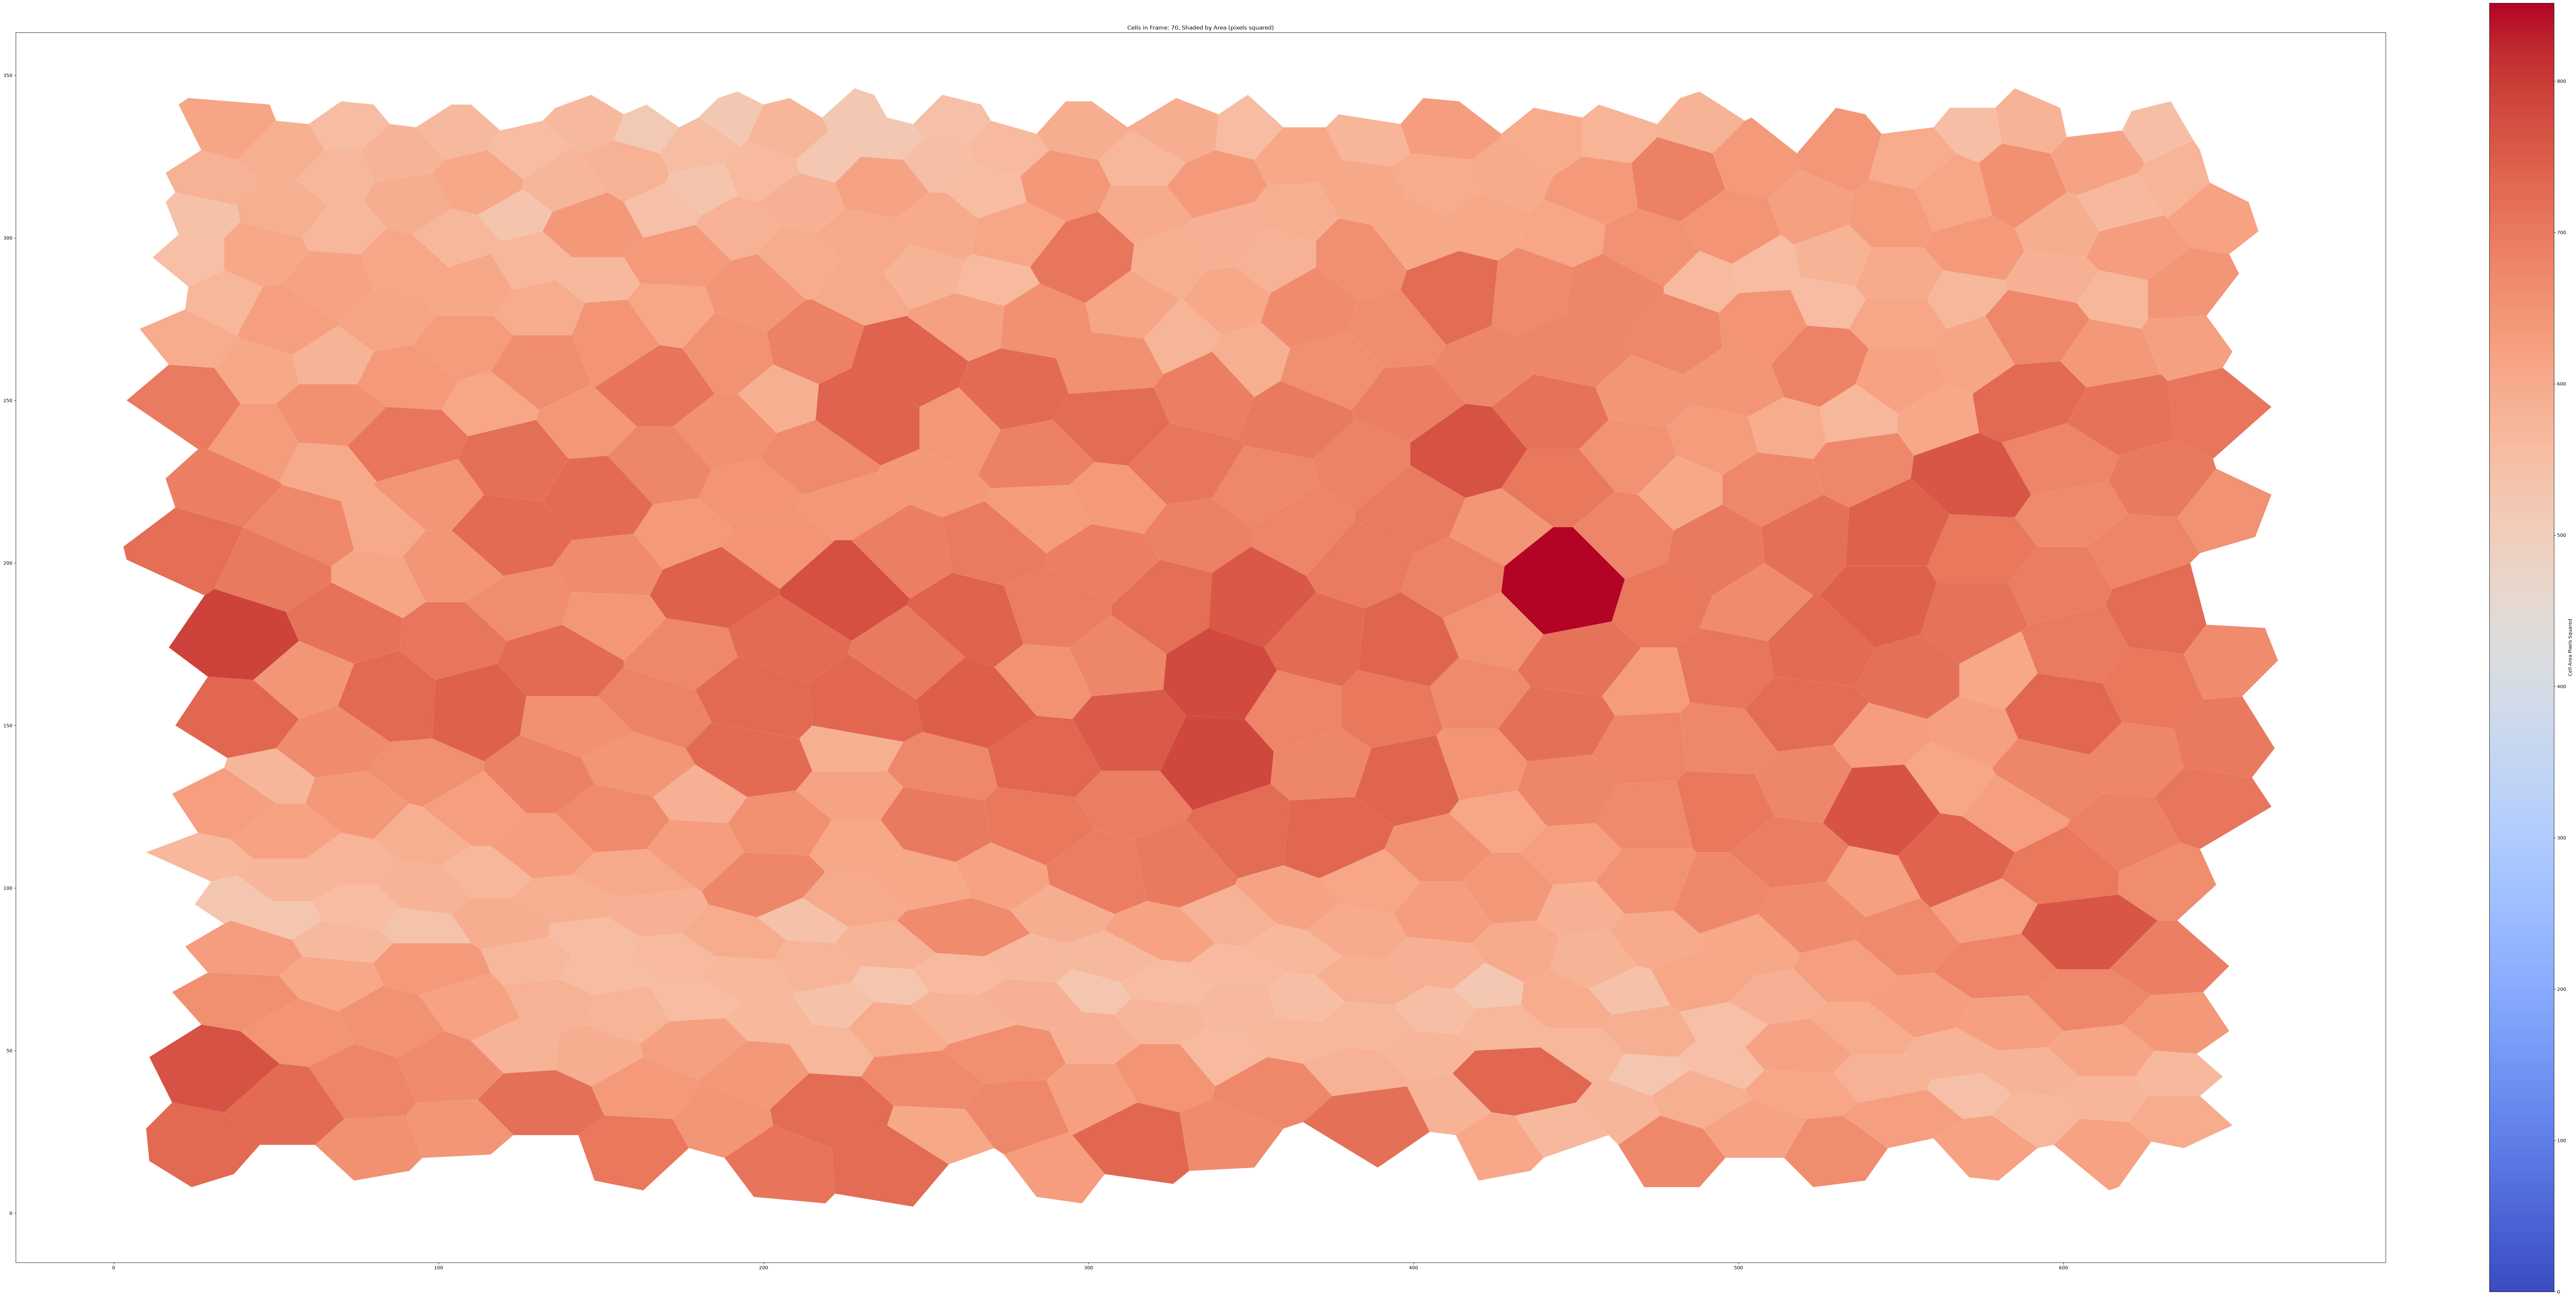

In [6]:
fig, ax = plt.subplots(figsize=(100,50))

shoelace_area_dict = dict(zip(cleaned_cell_data["cell_id"], shoelace_areas))

cellplot.draw_cell_boundaries(
    ax,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    shoelace_area_dict,
    border_width=0.001
)

ax.set_title(f"Cells in Frame: {frame}, Shaded by Area (pixels squared)")
cellplot.plotColorBar(ax, fig, shoelace_area_dict, False, "Cell Area Pixels Squared")

In [7]:
print(np.mean(list(n_order_dict.values())))
print(np.mean(list(hexatic_order_dict.values())))
np.mean(list(aspect_ratio_dict.values()))

0.8577218946823746
0.13656904


np.float64(1.5844862028368456)

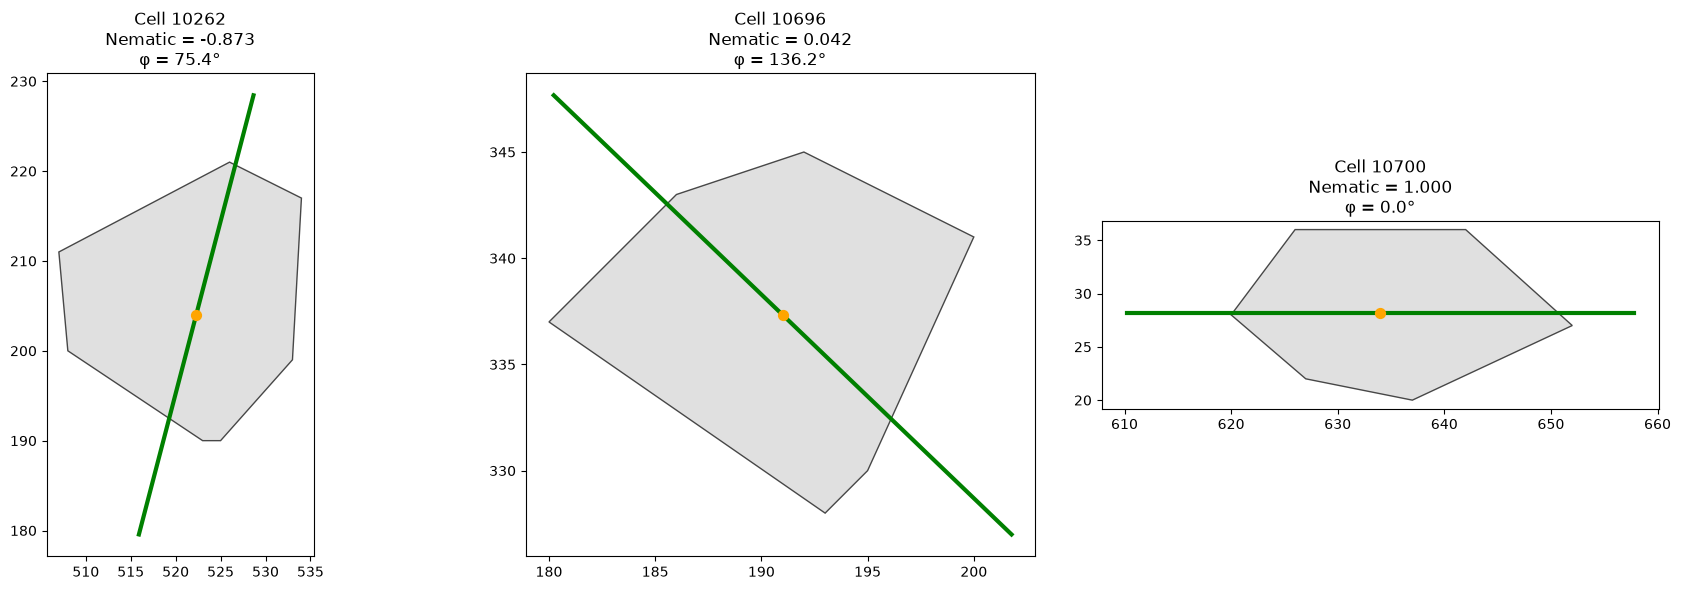

In [11]:
# Find interesting cells
lowest_cell = min(n_order_dict, key=n_order_dict.get)
highest_cell = max(n_order_dict, key=n_order_dict.get)
zero_cell = min(n_order_dict, key=lambda cid: abs(n_order_dict[cid]))

selected_cells = [lowest_cell, zero_cell, highest_cell]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

all_dbonds = dbonds_data
all_vertices = vertices_data

for ax, cell_id in zip(axes, selected_cells):

    # Get cell vertices
    cell_vertices = cellmath.get_cell_verticies(
        cell_id, all_dbonds, all_vertices
    )

    points = np.array([
        [v["x_pos"], v["y_pos"]]
        for v in cell_vertices
    ])

    # Cell center
    center = points.mean(axis=0)

    # Principal axis from covariance matrix
    covariance = np.cov(points, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    principal_axis = eigenvectors[:, np.argmax(eigenvalues)]

    # Convert principal axis -> phi
    phi = np.arctan2(
        principal_axis[1],
        principal_axis[0]
    )

    # Draw cell
    ax.fill(
        points[:, 0],
        points[:, 1],
        facecolor="lightgray",
        edgecolor="black",
        alpha=0.7
    )

    # Draw orange dot at center
    ax.scatter(
        center[0],
        center[1],
        color="orange",
        s=50,
        zorder=5
    )

    # Draw green principal/nematic axis
    length = np.sqrt(eigenvalues.max()) * 2

    dx = length * np.cos(phi)
    dy = length * np.sin(phi)

    ax.plot(
        [center[0] - dx, center[0] + dx],
        [center[1] - dy, center[1] + dy],
        color="green",
        linewidth=3
    )
    ax.set_title(
        f"Cell {cell_id}\n"
        f"Nematic = {n_order_dict[cell_id]:.3f}\n"
        f"φ = {np.degrees(phi):.1f}°"
    )

    ax.set_aspect("equal")

plt.tight_layout()
plt.show()